In [12]:
!pip install pgmpy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 46.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [pgmpy]


In [18]:
import statistics

ruang_sampel = [1, 2, 3, 4, 5, 6]
genap = [x for x in ruang_sampel if x % 2 == 0]

frekuensi = len(genap)
total = len(ruang_sampel)

p = statistics.mean(
    [1 if x % 2 == 0 else 0 for x in ruang_sampel]
)

print("Angka genap:", genap)
print("Frekuensi kejadian:", frekuensi)
print("Probabilitas:", p)
print("Persentase:", p * 100, "%")

Angka genap: [2, 4, 6]
Frekuensi kejadian: 3
Probabilitas: 0.5
Persentase: 50.0 %


In [2]:
from fractions import Fraction

ruang_sampel = [1, 2, 3, 4, 5, 6]
genap = [x for x in ruang_sampel if x % 2 == 0]

p = Fraction(len(genap), len(ruang_sampel))

print("Angka genap:", genap)
print("Probabilitas:", p)
print("Desimal:", float(p))
print("Persentase:", float(p) * 100, "%")

Angka genap: [2, 4, 6]
Probabilitas: 1/2
Desimal: 0.5
Persentase: 50.0 %


In [4]:
import numpy as np

rng = np.random.default_rng(42)
n = 100_000
hasil = rng.choice(["angka", "gambar"], size=n)
jumlah = int(np.sum(hasil == "gambar"))
print("Jumlah percobaan:", n)
print("Jumlah gambar:", jumlah)
print("Probabilitas empiris:", round(jumlah/n, 4))
print("Probabilitas teoretis:", 0.5)

Jumlah percobaan: 100000
Jumlah gambar: 50089
Probabilitas empiris: 0.5009
Probabilitas teoretis: 0.5


In [5]:
from fractions import Fraction
p = Fraction(13, 52)
print("Pecahan:", p)
print("Desimal:", float(p))


Pecahan: 1/4
Desimal: 0.25


In [7]:
from sympy import Rational

pengguna_linux = 60
linux_dan_python = 45

p = Rational(linux_dan_python, pengguna_linux)

print("P(Python | Linux) =", p)
print("Desimal =", float(p))
print("Persentase =", float(p) * 100, "%")

P(Python | Linux) = 3/4
Desimal = 0.75
Persentase = 75.0 %


In [14]:
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.factors.discrete import TabularCPD
from pgmpy.inference import VariableElimination

# Membuat Bayesian Network
model = DiscreteBayesianNetwork([("Spam", "Tanda")])

# Probabilitas email merupakan spam
cpd_spam = TabularCPD(
    variable="Spam",
    variable_card=2,
    values=[[0.80], [0.20]]
)

# Probabilitas tanda spam berdasarkan kondisi email
cpd_tanda = TabularCPD(
    variable="Tanda",
    variable_card=2,
    values=[
        [0.95, 0.10],
        [0.05, 0.90]
    ],
    evidence=["Spam"],
    evidence_card=[2]
)

model.add_cpds(cpd_spam, cpd_tanda)

# Melakukan inferensi
infer = VariableElimination(model)
hasil = infer.query(
    variables=["Spam"],
    evidence={"Tanda": 1}
)

posterior = hasil.values[1]

print("P(spam | ditandai):", round(posterior, 4))
print("Persentase:", round(posterior * 100, 2), "%")

P(spam | ditandai): 0.8182
Persentase: 81.82 %


In [15]:
from itertools import permutations, combinations

simbol = range(10)

# Menghitung seluruh susunan password
daftar_permutasi = list(permutations(simbol, 4))

# Menghitung kombinasi tanpa memperhatikan urutan
daftar_kombinasi = list(combinations(simbol, 4))

print("Kombinasi:", len(daftar_kombinasi))
print("Permutasi:", len(daftar_permutasi))

Kombinasi: 210
Permutasi: 5040


In [16]:
from decimal import Decimal

p = Decimal("0.98")
hasil = p * p

print("P(keduanya berhasil):", hasil)
print("Persentase:", hasil * 100, "%")

P(keduanya berhasil): 0.9604
Persentase: 96.0400 %


In [17]:
import random

random.seed(123)

n = 10_000
p_sukses = 0.95

berhasil = [
    random.random() < p_sukses
    for _ in range(n)
]

jumlah = sum(berhasil)
probabilitas_empiris = jumlah / n

print("Jumlah paket:", n)
print("Paket berhasil:", jumlah)
print("Probabilitas empiris:", round(probabilitas_empiris, 4))
print("Probabilitas teoretis:", p_sukses)

Jumlah paket: 10000
Paket berhasil: 9496
Probabilitas empiris: 0.9496
Probabilitas teoretis: 0.95


P(X=1): 0.95
P(X=0): 0.05
Mean: 0.95
Varians: 0.0475


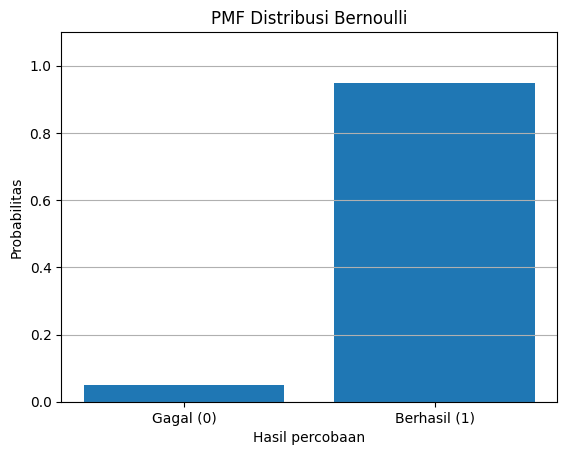

In [35]:
from scipy.stats import bernoulli
import matplotlib.pyplot as plt

p = 0.95

# Menghitung probabilitas
print("P(X=1):", round(bernoulli.pmf(1, p), 4))
print("P(X=0):", round(bernoulli.pmf(0, p), 4))
print("Mean:", round(bernoulli.mean(p), 4))
print("Varians:", round(bernoulli.var(p), 4))

# Visualisasi distribusi Bernoulli
x = [0, 1]
y = bernoulli.pmf(x, p)

plt.bar(x, y)
plt.xticks([0, 1], ["Gagal (0)", "Berhasil (1)"])
plt.xlabel("Hasil percobaan")
plt.ylabel("Probabilitas")
plt.title("PMF Distribusi Bernoulli")
plt.ylim(0, 1.1)
plt.grid(axis="y")
plt.show()

P(X=8): 0.1937
P(X<=8): 0.2639
Mean: 9.0
Varians: 0.9

Tabel Distribusi Binomial:
    Jumlah paket berhasil  Probabilitas
0                       0  1.000000e-10
1                       1  9.000000e-09
2                       2  3.645000e-07
3                       3  8.748000e-06
4                       4  1.377810e-04
5                       5  1.488035e-03
6                       6  1.116026e-02
7                       7  5.739563e-02
8                       8  1.937102e-01
9                       9  3.874205e-01
10                     10  3.486784e-01


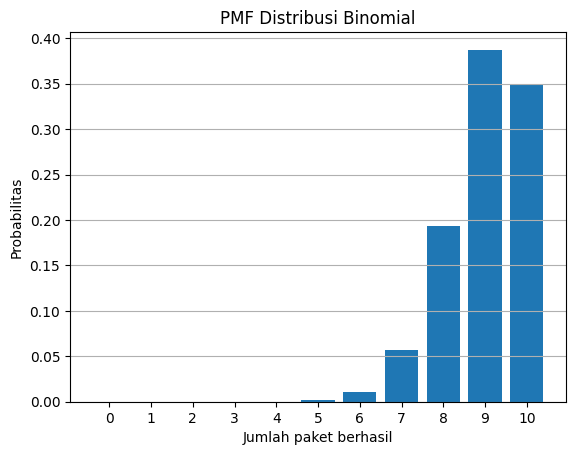

In [34]:
import pandas as pd
import matplotlib.pyplot as plt
import math

n, p, k = 10, 0.9, 8

# Menghitung probabilitas distribusi Binomial
x = range(n + 1)

probabilitas = [
    math.comb(n, i) * (p ** i) * ((1 - p) ** (n - i))
    for i in x
]

# Membuat tabel menggunakan Pandas
data = pd.DataFrame({
    "Jumlah paket berhasil": list(x),
    "Probabilitas": probabilitas
})

# Menghitung probabilitas dan karakteristik distribusi
print("P(X=8):", round(data.loc[k, "Probabilitas"], 4))
print("P(X<=8):", round(data.loc[:k, "Probabilitas"].sum(), 4))
print("Mean:", n * p)
print("Varians:", round(n * p * (1 - p), 4))

print("\nTabel Distribusi Binomial:")
print(data)

# Visualisasi
plt.bar(data["Jumlah paket berhasil"], data["Probabilitas"])
plt.xlabel("Jumlah paket berhasil")
plt.ylabel("Probabilitas")
plt.title("PMF Distribusi Binomial")
plt.xticks(list(x))
plt.grid(axis="y")
plt.show()

P(X=2): 0.1465
P(X<=2): 0.2381
Mean: 4
Varians: 4


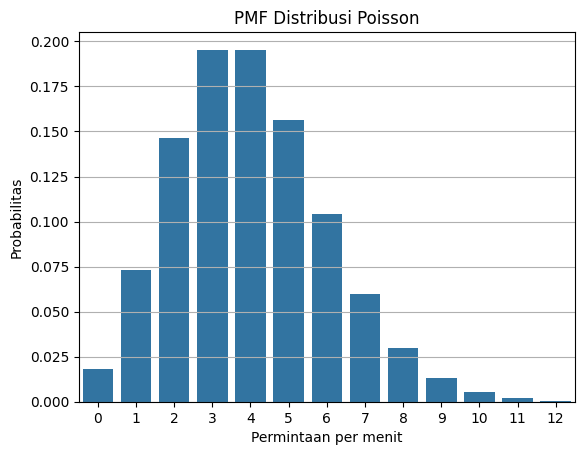

In [33]:
import math
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

lam, k = 4, 2

# Menghitung probabilitas
prob = math.exp(-lam) * (lam ** k) / math.factorial(k)

# Menghitung probabilitas kumulatif
prob_kumulatif = sum(
    math.exp(-lam) * (lam ** i) / math.factorial(i)
    for i in range(k + 1)
)

print("P(X=2):", round(prob, 4))
print("P(X<=2):", round(prob_kumulatif, 4))
print("Mean:", lam)
print("Varians:", lam)

# Menyiapkan data visualisasi
x = np.arange(0, 13)
y = [
    math.exp(-lam) * (lam ** i) / math.factorial(i)
    for i in x
]

# Visualisasi menggunakan Seaborn
sns.barplot(x=x, y=y)
plt.xlabel("Permintaan per menit")
plt.ylabel("Probabilitas")
plt.title("PMF Distribusi Poisson")
plt.grid(axis="y")
plt.show()

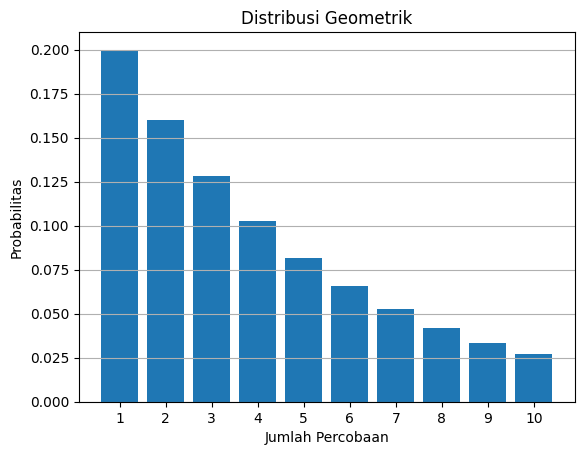

P(X=3): 0.128
Mean: 5.0
Varians: 19.999999999999996


In [30]:
import mpmath as mp
import matplotlib.pyplot as plt

p = mp.mpf('0.2')
k = 3

# Menghitung probabilitas sukses pertama pada percobaan ke-3
prob = (1 - p) ** (k - 1) * p

# Menghitung mean dan varians
mean = 1 / p
varians = (1 - p) / (p ** 2)

# Menghitung probabilitas untuk percobaan ke-1 sampai ke-10
percobaan = range(1, 11)
peluang = [(1 - float(p)) ** (i - 1) * float(p)
           for i in percobaan]

# Membuat grafik distribusi geometrik
plt.bar(percobaan, peluang)
plt.xlabel("Jumlah Percobaan")
plt.ylabel("Probabilitas")
plt.title("Distribusi Geometrik")
plt.xticks(list(percobaan))
plt.grid(axis="y")
plt.show()

print("P(X=3):", float(mp.nstr(prob, 5)))
print("Mean:", float(mean))
print("Varians:", float(varians))

P(170 <= X <= 230): 0.6827
Mean: 200
Varians: 900


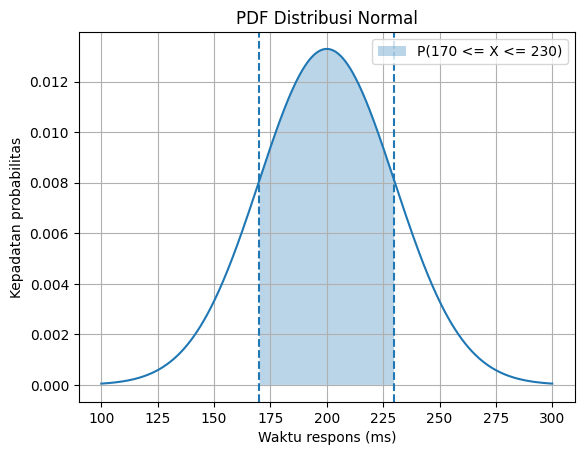

In [29]:
from statsmodels.distributions.empirical_distribution import ECDF
from scipy.special import ndtr
import numpy as np
import matplotlib.pyplot as plt

mu, sigma = 200, 30

# Menghitung probabilitas distribusi normal
prob = ndtr((230 - mu) / sigma) - ndtr((170 - mu) / sigma)

mean = mu
varians = sigma ** 2

print("P(170 <= X <= 230):", round(prob, 4))
print("Mean:", mean)
print("Varians:", varians)

# Visualisasi PDF Distribusi Normal
x = np.linspace(100, 300, 400)
y = (1 / (sigma * np.sqrt(2 * np.pi))) * np.exp(
    -0.5 * ((x - mu) / sigma) ** 2
)

plt.plot(x, y)
plt.fill_between(x, y, where=(x >= 170) & (x <= 230),
                 alpha=0.3, label="P(170 <= X <= 230)")
plt.axvline(170, linestyle="--")
plt.axvline(230, linestyle="--")
plt.xlabel("Waktu respons (ms)")
plt.ylabel("Kepadatan probabilitas")
plt.title("PDF Distribusi Normal")
plt.legend()
plt.grid(True)
plt.show()

P(X > 3): 0.2231
Mean: 2
Varians: 4.0


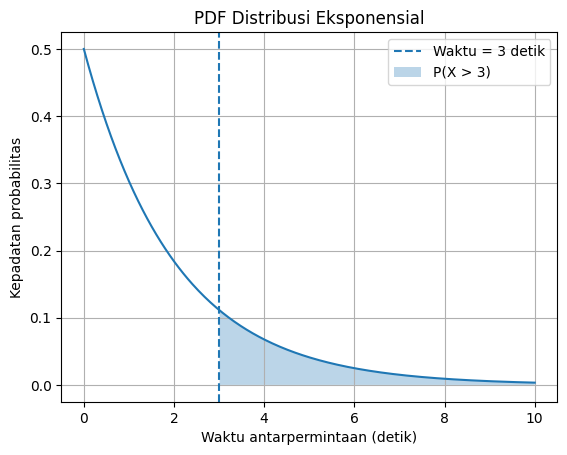

In [27]:
import math
import numpy as np
import matplotlib.pyplot as plt

mean = 2
waktu = 3

lam = 1 / mean

# Menghitung probabilitas
prob = math.exp(-lam * waktu)
varians = 1 / (lam ** 2)

print("P(X > 3):", round(prob, 4))
print("Mean:", mean)
print("Varians:", varians)

# Membuat grafik PDF Distribusi Eksponensial
x = np.linspace(0, 10, 300)
y = lam * np.exp(-lam * x)

plt.plot(x, y)
plt.axvline(waktu, linestyle="--", label="Waktu = 3 detik")
plt.fill_between(x, y, where=(x >= waktu), alpha=0.3,
                 label="P(X > 3)")
plt.xlabel("Waktu antarpermintaan (detik)")
plt.ylabel("Kepadatan probabilitas")
plt.title("PDF Distribusi Eksponensial")
plt.legend()
plt.grid(True)
plt.show()

In [25]:
!pip install tensorflow-probability

P(2 <= X <= 5): 0.3
Mean: 5.0
Varians: 8.3333


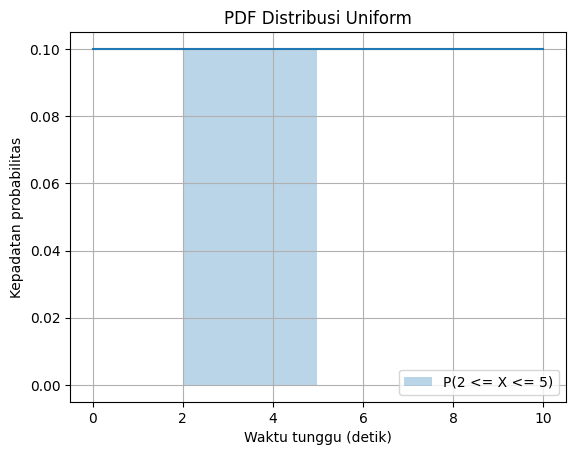

In [28]:
import tensorflow_probability as tfp
import numpy as np
import matplotlib.pyplot as plt

tfd = tfp.distributions

a, b = 0.0, 10.0

# Membuat distribusi uniform
distribusi = tfd.Uniform(low=a, high=b)

# Menghitung probabilitas, mean, dan varians
prob = distribusi.cdf(5.0) - distribusi.cdf(2.0)

print("P(2 <= X <= 5):", round(float(prob.numpy()), 4))
print("Mean:", float(distribusi.mean().numpy()))
print("Varians:", round(float(distribusi.variance().numpy()), 4))

# Visualisasi PDF Distribusi Uniform
x = np.linspace(a, b, 200)
y = np.where((x >= a) & (x <= b), 1 / (b - a), 0)

plt.plot(x, y)
plt.fill_between(x, y, where=(x >= 2) & (x <= 5),
                 alpha=0.3, label="P(2 <= X <= 5)")
plt.xlabel("Waktu tunggu (detik)")
plt.ylabel("Kepadatan probabilitas")
plt.title("PDF Distribusi Uniform")
plt.legend()
plt.grid(True)
plt.show()